# Repeat Purchase Prediction
Use a customer's first order to see if they come back, and whether a bad first experience lowers that chance.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score

In [2]:
path = "../Data/Processed/"

orders = pd.read_csv(path + "orders_clean.csv", parse_dates=["order_purchase_timestamp"])
items = pd.read_csv(path + "order_items_clean.csv")
products = pd.read_csv(path + "products_clean.csv")
customers = pd.read_csv(path + "customers_clean.csv", dtype={"customer_zip_code_prefix": str})
payments = pd.read_csv(path + "payments_clean.csv")
reviews = pd.read_csv(path + "reviews_by_order_clean.csv")

scope = orders[orders["in_analysis_scope"] == True].sort_values("order_purchase_timestamp")
print(len(scope), "orders,", scope["customer_unique_id"].nunique(), "customers")

96470 orders, 93350 customers


### Which customers came back?

In [3]:
n_orders = scope.groupby("customer_unique_id")["order_id"].count()

first = scope.drop_duplicates("customer_unique_id").copy()
first["repeat"] = (first["customer_unique_id"].map(n_orders) > 1).astype(int)

print("repeat rate:", round(first["repeat"].mean() * 100, 2), "%")

repeat rate: 3.0 %


In [4]:
# keep first orders before Mar 2018 so everyone had 6+ months to come back
first = first[first["order_purchase_timestamp"] < "2018-03-01"]
print(len(first), "customers, repeat rate", round(first["repeat"].mean() * 100, 2), "%")

55523 customers, repeat rate 3.98 %


In [5]:
items = items.merge(products[["product_id", "product_category_name_english"]], on="product_id", how="left")
order_items = items.groupby("order_id").agg(n_items=("order_item_id", "count"),
                                            price=("price", "sum"),
                                            freight=("freight_value", "sum")).reset_index()
order_items["freight_ratio"] = order_items["freight"] / order_items["price"]
first_cat = items[items["order_item_id"] == 1][["order_id", "product_category_name_english"]]

pay_type = payments.sort_values("payment_value", ascending=False).drop_duplicates("order_id")[["order_id", "payment_type"]]
installments = payments.groupby("order_id")["payment_installments"].max().reset_index()

df = first[["order_id", "customer_id", "customer_unique_id", "order_purchase_timestamp", "delivery_days", "is_late", "repeat"]]
df = (df.merge(order_items, on="order_id", how="left")
        .merge(first_cat, on="order_id", how="left")
        .merge(pay_type, on="order_id", how="left")
        .merge(installments, on="order_id", how="left")
        .merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")
        .merge(reviews[["order_id", "review_score"]], on="order_id", how="left"))

df["was_late"] = df["is_late"].astype(int)
df["month"] = df["order_purchase_timestamp"].dt.month
df.head()

,order_id,customer_id,customer_unique_id,order_purchase_timestamp,delivery_days,is_late,repeat,n_items,price,freight,freight_ratio,product_category_name_english,payment_type,payment_installments,customer_state,review_score,was_late,month
0,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,830d5b7aaa3b6f1e9ad63703bec97d23,2016-09-15 12:16:38,54.0,True,0,3,134.97,8.49,0.062903,health_beauty,NaN,NaN,SP,1.0,1,9
1,3b697a20d9e427646d92567910af6d57,355077684019f7f60a031656bd7262b8,32ea3bdedab835c3aa6cb68ce66565ef,2016-10-03 09:44:50,23.0,False,1,1,29.90,15.56,0.520401,watches_gifts,boleto,1.0,SP,4.0,0,10
2,be5bc2f0da14d8071e2d45451ad119d9,7ec40b22510fdbea1b08921dd39e63d8,2f64e403852e6893ae37485d5fcacdaf,2016-10-03 16:56:50,24.0,False,0,1,21.90,17.19,0.784932,sports_leisure,boleto,1.0,RS,4.0,0,10
3,a41c8759fbe7aab36ea07e038b2d4465,6f989332712d3222b6571b1cf5b835ce,61db744d2f835035a5625b59350c6b63,2016-10-03 21:13:36,30.0,False,0,1,36.49,17.24,0.472458,sports_leisure,boleto,1.0,RS,3.0,0,10
4,d207cc272675637bfed0062edffd0818,b8cf418e97ae795672d326288dfab7a7,8d3a54507421dbd2ce0a1d58046826e0,2016-10-03 22:06:03,27.0,False,0,1,119.90,13.56,0.113094,furniture_decor,credit_card,6.0,SP,1.0,0,10


### Do customers with a late first order come back less?

In [6]:
df.groupby("was_late")["repeat"].agg(customers="count", repeat_rate="mean").round(4)

,customers,repeat_rate
was_late,,
0,51849,0.0405
1,3674,0.0302


### Does the first review score matter?

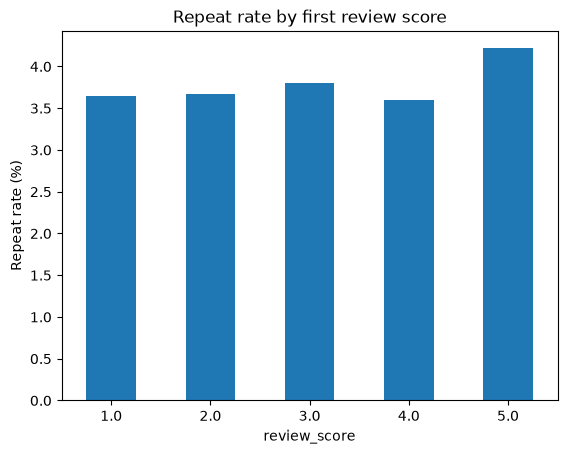

,customers,repeat_rate
review_score,,
1.0,5485,0.0365
2.0,1769,0.0367
3.0,4810,0.0380
4.0,11069,0.0360
5.0,31977,0.0422


In [7]:
by_score = df.groupby("review_score")["repeat"].agg(customers="count", repeat_rate="mean")

(by_score["repeat_rate"] * 100).plot(kind="bar", rot=0)
plt.title("Repeat rate by first review score")
plt.ylabel("Repeat rate (%)")
plt.show()

by_score.round(4)

### Repeat rate in the top 10 states

In [8]:
top_states = df["customer_state"].value_counts().head(10).index
df[df["customer_state"].isin(top_states)].groupby("customer_state")["repeat"].mean().sort_values(ascending=False).round(4)

customer_state
SP    0.0427
RJ    0.0419
RS    0.0411
ES    0.0394
MG    0.0387
PR    0.0386
DF    0.0382
GO    0.0381
BA    0.0361
SC    0.0314
Name: repeat, dtype: float64

In [9]:
df["has_review"] = df["review_score"].notna().astype(int)
df["review_score"] = df["review_score"].fillna(df["review_score"].median())

top_cats = df["product_category_name_english"].value_counts().head(15).index
df["category"] = df["product_category_name_english"].where(df["product_category_name_english"].isin(top_cats), "other")

num_cols = ["price", "n_items", "freight", "freight_ratio", "payment_installments",
            "was_late", "delivery_days", "review_score", "has_review", "month"]
cat_cols = ["category", "customer_state", "payment_type"]

X = df[num_cols + cat_cols].copy()
X[num_cols] = X[num_cols].fillna(X[num_cols].median())
X[cat_cols] = X[cat_cols].fillna("missing")
X = pd.get_dummies(X, columns=cat_cols, dtype=int)
y = df["repeat"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
X_train.shape, X_test.shape

((41642, 58), (13881, 58))

### Can the first order predict a second one?

In [10]:
lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
lr.fit(X_train, y_train)
lr_prob = lr.predict_proba(X_test)[:, 1]

rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=50,
                            class_weight="balanced_subsample", random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_prob = rf.predict_proba(X_test)[:, 1]

print("baseline PR AUC:", round(y_test.mean(), 3))
pd.DataFrame({
    "model": ["Logistic regression", "Random forest"],
    "ROC AUC": [roc_auc_score(y_test, lr_prob), roc_auc_score(y_test, rf_prob)],
    "PR AUC": [average_precision_score(y_test, lr_prob), average_precision_score(y_test, rf_prob)]}).round(3)

baseline PR AUC: 0.04


,model,ROC AUC,PR AUC
0,Logistic regression,0.599,0.060
1,Random forest,0.611,0.061


### If we target the top 10% by score, how much better is it than random?

In [11]:
res = pd.DataFrame({"repeat": y_test, "score": rf_prob})
top = res.nlargest(int(len(res) * 0.1), "score")

print("repeat rate overall:", round(res["repeat"].mean() * 100, 2), "%")
print("repeat rate in top 10%:", round(top["repeat"].mean() * 100, 2), "%")
print("lift:", round(top["repeat"].mean() / res["repeat"].mean(), 2))

repeat rate overall: 3.98 %
repeat rate in top 10%: 7.06 %
lift: 1.78


### Which features matter most?

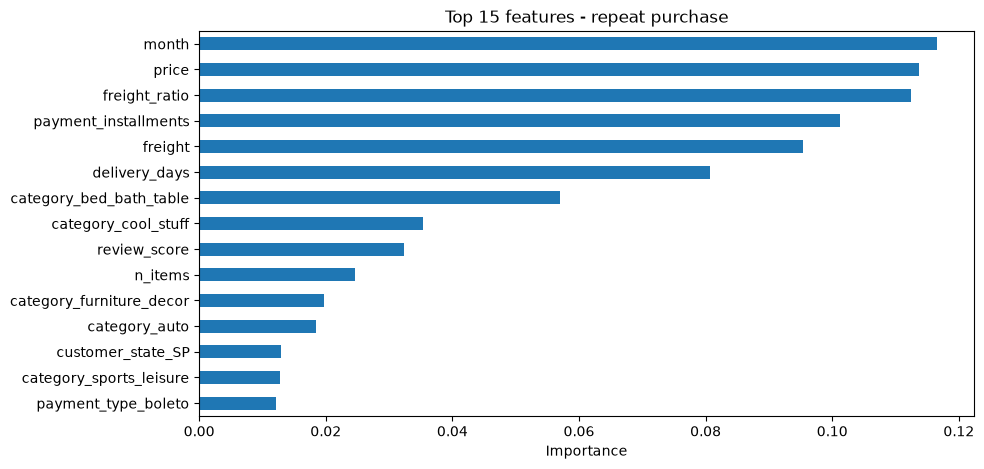

In [12]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

imp.head(15).sort_values().plot(kind="barh", figsize=(10, 5))
plt.title("Top 15 features - repeat purchase")
plt.xlabel("Importance")
plt.show()

In [13]:
df["repeat_score"] = rf.predict_proba(X)[:, 1]
df[["customer_unique_id", "order_purchase_timestamp", "customer_state", "category", "price",
    "was_late", "review_score", "repeat_score", "repeat"]].to_csv(path + "repeat_purchase_scores.csv", index=False)

## Observations

- Customers kept: 55,523 with a first order before Mar 2018 (repeat rate 3.98%, compared with 3.0% for all customers)
- Repeat rate after on-time first order: 4.05% | after late first order: 3.02%. Customers whose first order was late came back about 25% less often.
- Repeat rate by first review score: 5 stars 4.22%; 1 to 4 stars all between 3.60% and 3.80%. Only a 5-star first experience stands out.
- Repeat rate by state (top 10 states): highest in SP (4.27%) and RJ (4.19%), lowest in SC (3.14%)
- Logistic regression ROC AUC: 0.599 | Random forest ROC AUC: 0.611
- PR AUC: 0.060 (logistic regression) and 0.061 (random forest) vs 0.040 baseline
- Top 10% by score (random forest): 7.06% repeat vs 3.98% overall (lift 1.78)
- Strongest predictors (random forest): month of first order, price, freight ratio, number of installments, freight, delivery days, and the bed_bath_table and cool_stuff categories. Review score ranked lower, and a late first order did not make the top 15.
- Business takeaway: the first order alone is a weak predictor of a second purchase, but the scores still help. Targeting the top 10% of customers finds repeat buyers 1.78 times more often than picking at random, which could cut the cost of a second-purchase campaign. Delivering the first order on time and earning a 5-star review are linked to more repeat buying, so delivery quality matters for retention as well as for reviews.
- Limitations: very few repeat buyers to learn from; only first-order data is used; customers had different amounts of time to come back (6 to 23 months), and the month feature partly reflects this; the links between late delivery, reviews and repeat buying are patterns, not proof of cause.